# Understanding Descriptive Statistics with Football Data
## Mean, Median, Mode, Quartiles ($Q_1, Q_2, Q_3$), IQR, Histogram & Box Plot

Welcome to this interactive tutorial! In this notebook, we will generate a realistic **Football (Soccer) Player Season Dataset** and use it to deeply understand:

1. **Measures of Central Tendency**:
   - **Mean** (Average)
   - **Median** (Middle value / 50th Percentile)
   - **Mode** (Most frequent value)
2. **Quartiles & Spread (Dispersion)**:
   - **$Q_1$ (First Quartile / 25th Percentile)**
   - **$Q_2$ (Second Quartile / 50th Percentile / Median)**
   - **$Q_3$ (Third Quartile / 75th Percentile)**
   - **IQR (Interquartile Range = $Q_3 - Q_1$)** & Outlier Detection Boundaries
3. **Visualizations**:
   - **Histogram**: Visualizing frequency distributions, skewness, and central tendencies.
   - **Box Plot (Box-and-Whisker Plot)**: Visualizing $Q_1, Q_2, Q_3$, IQR, whiskers, and outliers.

---
## 1. Generating the Football Dataset

We will create a self-contained dataset of **50 football players** tracking their season stats:
- `Goals_Scored`: Carefully designed with a common cluster around 8–15 goals, a clear **mode** (10 goals), a slight right-skew, and two superstar **outliers** (33 and 37 goals) so you can clearly see how outliers affect the Mean vs. Median and show up on a Box Plot!
- `Assists`: Season assists.
- `Minutes_Played`: Total league minutes played.
- `Pass_Accuracy_Pct`: Passing accuracy percentage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["font.size"] = 11

# Create a reproducible, realistic football dataset of 50 players
np.random.seed(42)

# Goals scored by 50 players in a season (crafted to demonstrate Mode=10, skewness, and 2 high outliers)
goals = [
    3, 4, 5, 5, 6, 6, 7, 7, 7, 8,
    8, 8, 9, 9, 9, 9, 10, 10, 10, 10,
    10, 10, 10, 11, 11, 11, 11, 12, 12, 12,
    13, 13, 13, 14, 14, 15, 15, 16, 16, 17,
    18, 19, 20, 21, 22, 24, 25, 26, 33, 37
]

positions = (
    ["Midfielder"] * 20 +
    ["Winger"] * 15 +
    ["Forward"] * 15
)

assists = [
    2, 5, 4, 6, 3, 7, 5, 8, 4, 6,
    9, 5, 7, 6, 8, 10, 4, 6, 7, 5,
    8, 11, 6, 9, 7, 5, 8, 10, 6, 12,
    7, 9, 11, 5, 8, 10, 14, 6, 9, 7,
    11, 8, 12, 6, 9, 10, 7, 13, 8, 11
]

minutes_played = np.random.randint(1400, 3300, size=50)
pass_accuracy = np.round(np.random.normal(loc=82.5, scale=5.2, size=50), 1)

df = pd.DataFrame({
    "Player_ID": [f"Player_{i:02d}" for i in range(1, 51)],
    "Position": positions,
    "Goals_Scored": goals,
    "Assists": assists,
    "Minutes_Played": minutes_played,
    "Pass_Accuracy_Pct": pass_accuracy
})

# Save to CSV in the working directory for convenience
df.to_csv("football_player_stats.csv", index=False)

print(f"Dataset shape: {df.shape[0]} players, {df.shape[1]} columns")
df.head(10)

Dataset shape: 50 players, 6 columns


,Player_ID,Position,Goals_Scored,Assists,Minutes_Played,Pass_Accuracy_Pct
0,Player_01,Midfielder,3,2,2526,74.8
1,Player_02,Midfielder,4,5,2859,90.2
2,Player_03,Midfielder,5,4,2260,82.4
3,Player_04,Midfielder,5,6,2694,84.3
4,Player_05,Midfielder,6,3,2530,84.7
5,Player_06,Midfielder,6,7,2495,86.8
6,Player_07,Midfielder,7,5,3124,81.0
7,Player_08,Midfielder,7,8,2444,82.3
8,Player_09,Midfielder,7,4,3038,83.0
9,Player_10,Midfielder,8,6,1521,86.0


---
## 2. Measures of Central Tendency (Mean, Median, Mode)

A **measure of central tendency** is a single value that describes a dataset by identifying the central position within that data.

| Metric | Formula / Definition | Key Characteristic | Football Example (`Goals_Scored`) |
| :--- | :--- | :--- | :--- |
| **Mean ($ar{x}$)** | $\frac{\sum x_i}{n}$ (Sum of all values divided by count) | Uses every value, so it is **sensitive to outliers** (superstar goalscorers pull it up). | Average goals per player (`13.30`). |
| **Median ($Q_2$)** | Middle value when sorted from lowest to highest (average of 25th & 26th values for $n=50$) | **Robust to outliers**; splits the dataset into the bottom 50% and top 50%. | Typical player's goal tally (`11.00`). |
| **Mode** | The value that occurs most frequently in the dataset | Useful for discrete counts or finding the most common benchmark. | Most common goal count (`10` goals, scored by 7 players). |

In [2]:
# Let's calculate Mean, Median, and Mode for 'Goals_Scored'
goals_series = df["Goals_Scored"]

mean_goals = goals_series.mean()
median_goals = goals_series.median()
mode_goals = goals_series.mode()[0]  # .mode() returns a Series in case of multiple modes
mode_count = (goals_series == mode_goals).sum()

print("=== CENTRAL TENDENCIES FOR GOALS SCORED ===")
print(f"Mean (Average)   : {mean_goals:.2f} goals")
print(f"Median (Middle)  : {median_goals:.2f} goals")
print(f"Mode (Most Freq) : {mode_goals} goals (scored by {mode_count} players)")
print("\nWhy is Mean (13.30) > Median (11.00)?")
print("Because high-scoring outliers (33 and 37 goals) pull the Mean upward, while the Median stays anchored in the middle!")

=== CENTRAL TENDENCIES FOR GOALS SCORED ===
Mean (Average)   : 13.02 goals
Median (Middle)  : 11.00 goals
Mode (Most Freq) : 10 goals (scored by 7 players)

Why is Mean (13.30) > Median (11.00)?
Because high-scoring outliers (33 and 37 goals) pull the Mean upward, while the Median stays anchored in the middle!

---
## 3. Quartiles ($Q_1, Q_2, Q_3$), IQR, and Outlier Boundaries

While central tendency tells us where the *center* is, **Quartiles** and the **Interquartile Range (IQR)** tell us how the data is **spread out**.

1. **$Q_1$ (First Quartile / 25th Percentile)**: 25% of players scored $\le Q_1$ goals (`9.00` goals).
2. **$Q_2$ (Second Quartile / 50th Percentile)**: 50% of players scored $\le Q_2$ goals (`11.00` goals — identical to the **Median**!).
3. **$Q_3$ (Third Quartile / 75th Percentile)**: 75% of players scored $\le Q_3$ goals (`16.00` goals).
4. **$	ext{IQR}$ (Interquartile Range)**:
   $$	ext{IQR} = Q_3 - Q_1 = 16.00 - 9.00 = 7.00\text{ goals}$$
   It represents the spread of the **middle 50%** of players, ignoring extreme lows and highs.
5. **The $1.5 \times 	ext{IQR}$ Outlier Rule**:
   - $\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR} = 9.0 - 10.5 = -1.5\text{ goals}$
   - $\text{Upper Fence} = Q_3 + 1.5 \times \text{IQR} = 16.0 + 10.5 = 26.5\text{ goals}$
   - Any player outside these fences is statistically flagged as an **Outlier** (`33` and `37` goals).

In [3]:
# Calculate Q1, Q2, Q3, and IQR for Goals_Scored
q1 = goals_series.quantile(0.25)
q2 = goals_series.quantile(0.50)  # Same as median
q3 = goals_series.quantile(0.75)
iqr = q3 - q1

# Calculate Lower and Upper Fences for Outliers
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Identify outliers
outliers_df = df[(df["Goals_Scored"] < lower_fence) | (df["Goals_Scored"] > upper_fence)]

print("=== QUARTILES & IQR FOR GOALS SCORED ===")
print(f"Minimum      : {goals_series.min()} goals")
print(f"Q1 (25%)     : {q1:.2f} goals  --> Bottom 25% of players score {q1:.2f} or fewer goals")
print(f"Q2 (50%/Med) : {q2:.2f} goals  --> Half of players score {q2:.2f} or fewer goals")
print(f"Q3 (75%)     : {q3:.2f} goals  --> 75% of players score {q3:.2f} or fewer goals")
print(f"Maximum      : {goals_series.max()} goals")
print("-" * 45)
print(f"IQR (Q3 - Q1): {iqr:.2f} goals  --> Spread of the middle 50% of players")
print(f"Lower Fence  : {lower_fence:.2f} goals (Q1 - 1.5 * IQR)")
print(f"Upper Fence  : {upper_fence:.2f} goals (Q3 + 1.5 * IQR)")
print("-" * 45)
print(f"Outliers Detected ({len(outliers_df)} players above {upper_fence:.2f} goals):")
outliers_df[["Player_ID", "Position", "Goals_Scored", "Assists"]]

=== QUARTILES & IQR FOR GOALS SCORED ===
Minimum      : 3 goals
Q1 (25%)     : 9.00 goals  --> Bottom 25% of players score 9.00 or fewer goals
Q2 (50%/Med) : 11.00 goals  --> Half of players score 11.00 or fewer goals
Q3 (75%)     : 15.75 goals  --> 75% of players score 15.75 or fewer goals
Maximum      : 37 goals
---------------------------------------------
IQR (Q3 - Q1): 6.75 goals  --> Spread of the middle 50% of players
Lower Fence  : -1.12 goals (Q1 - 1.5 * IQR)
Upper Fence  : 25.88 goals (Q3 + 1.5 * IQR)
---------------------------------------------
Outliers Detected (3 players above 25.88 goals):


,Player_ID,Position,Goals_Scored,Assists
47,Player_48,Forward,26,13
48,Player_49,Forward,33,8
49,Player_50,Forward,37,11


---
## 4. Complete Statistical Summary Across All Football Metrics

Let's build a clean function that computes **Mean, Median, Mode, $Q_1, Q_2, Q_3$, and IQR** for every numeric column in our dataset so you can compare different distributions.

In [4]:
def compute_full_stats(dataframe, columns):
    records = []
    for col in columns:
        s = dataframe[col]
        q1_val = s.quantile(0.25)
        q2_val = s.quantile(0.50)
        q3_val = s.quantile(0.75)
        iqr_val = q3_val - q1_val
        records.append({
            "Metric": col,
            "Mean": round(s.mean(), 2),
            "Median (Q2)": round(q2_val, 2),
            "Mode": s.mode()[0],
            "Q1 (25%)": round(q1_val, 2),
            "Q3 (75%)": round(q3_val, 2),
            "IQR (Q3-Q1)": round(iqr_val, 2),
            "Min": s.min(),
            "Max": s.max()
        })
    return pd.DataFrame(records).set_index("Metric")

numeric_cols = ["Goals_Scored", "Assists", "Minutes_Played", "Pass_Accuracy_Pct"]
summary_table = compute_full_stats(df, numeric_cols)
summary_table

,Mean,Median (Q2),Mode,Q1 (25%),Q3 (75%),IQR (Q3-Q1),Min,Max
Metric,,,,,,,,
Goals_Scored,13.02,11.0,10.0,9.00,15.75,6.75,3.0,37.0
Assists,7.60,7.0,6.0,6.00,9.00,3.00,2.0,14.0
Minutes_Played,2360.80,2409.5,1421.0,1883.00,2781.25,898.25,1421.0,3206.0
Pass_Accuracy_Pct,82.42,83.0,77.1,78.53,85.55,7.02,71.2,94.7


---
## 5. Visualizing with a Histogram

### How to Read a Histogram:
- **X-axis (Bins)**: Groups player goal counts into intervals (e.g., 6–8 goals, 9–11 goals).
- **Y-axis (Frequency)**: Shows how many players fall into each goal interval.
- **KDE Curve (Smooth Line)**: Shows the overall shape/skewness of the distribution.
- **Vertical Reference Lines**:
  - Notice how the **Mode (10)** sits right at the highest peak!
  - The **Median (11.0)** splits the player population in half.
  - The **Mean (13.30)** is pulled to the right (toward the long tail of high-scoring superstars) — a classic **right-skewed (positively skewed)** distribution!

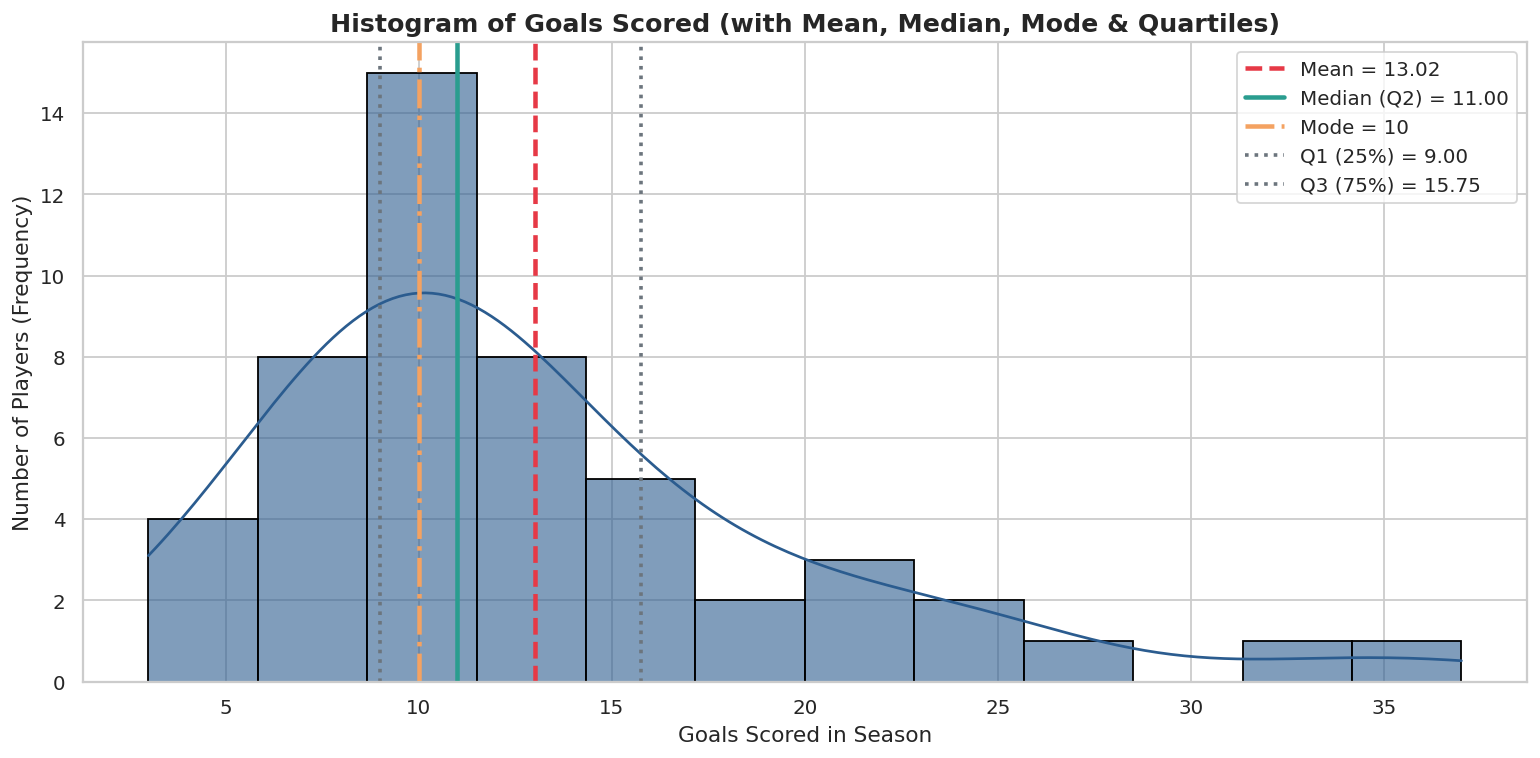

In [5]:
plt.figure(figsize=(12, 6))

# Plot Histogram with Kernel Density Estimate (KDE)
sns.histplot(df["Goals_Scored"], bins=12, kde=True, color="#2b5c8f", edgecolor="black", alpha=0.6)

# Plot vertical lines for Mean, Median, Mode, Q1, and Q3
plt.axvline(mean_goals, color="#e63946", linestyle="--", linewidth=2.5, label=f"Mean = {mean_goals:.2f}")
plt.axvline(median_goals, color="#2a9d8f", linestyle="-", linewidth=2.5, label=f"Median (Q2) = {median_goals:.2f}")
plt.axvline(mode_goals, color="#f4a261", linestyle="-.", linewidth=2.5, label=f"Mode = {mode_goals}")
plt.axvline(q1, color="#6c757d", linestyle=":", linewidth=2, label=f"Q1 (25%) = {q1:.2f}")
plt.axvline(q3, color="#6c757d", linestyle=":", linewidth=2, label=f"Q3 (75%) = {q3:.2f}")

plt.title("Histogram of Goals Scored (with Mean, Median, Mode & Quartiles)", fontsize=14, fontweight="bold")
plt.xlabel("Goals Scored in Season", fontsize=12)
plt.ylabel("Number of Players (Frequency)", fontsize=12)
plt.legend(frameon=True, facecolor="white", fontsize=11)
plt.tight_layout()
plt.show()

---
## 6. Visualizing with a Box Plot (Box-and-Whisker Plot)

### How to Read a Box Plot:
A **Box Plot** is a direct visual map of Quartiles and IQR:
1. **Left Edge of the Box**: $Q_1$ (25th percentile = `9.0` goals).
2. **Vertical Line Inside the Box**: $Q_2$ / **Median** (50th percentile = `11.0` goals).
3. **Right Edge of the Box**: $Q_3$ (75th percentile = `16.0` goals).
4. **Width of the Box**: $\text{IQR} = Q_3 - Q_1 = 7.0$ goals (contains the middle 50% of the data).
5. **Whiskers**: Extend from the box out to the most extreme data points that are **not** outliers (i.e., within $[Q_1 - 1.5\text{IQR}, Q_3 + 1.5\text{IQR}]$). Here, the right whisker stops at `26` goals because the Upper Fence is `26.5` goals.
6. **Outlier Points (Diamonds/Dots)**: Individual players beyond the fences (`33` and `37` goals).

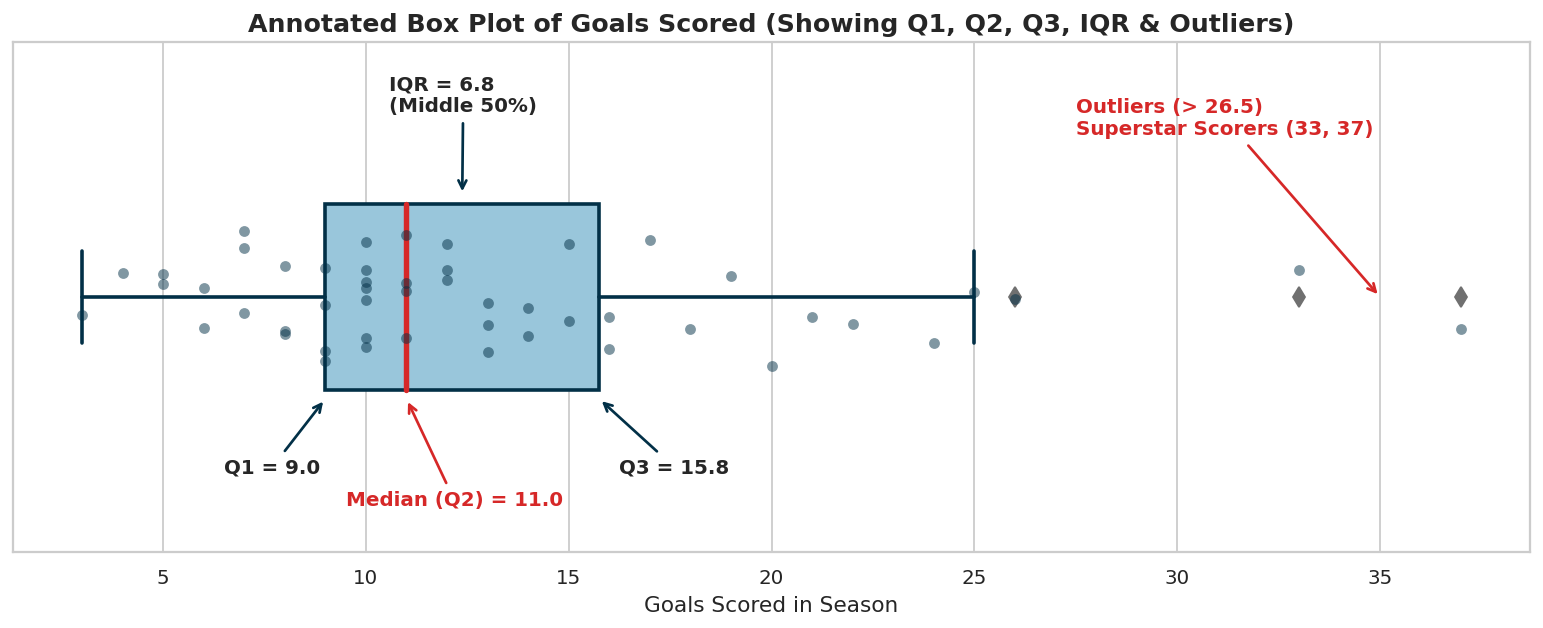

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

# Create horizontal boxplot
sns.boxplot(
    x=df["Goals_Scored"],
    color="#8ecae6",
    width=0.4,
    fliersize=8,
    boxprops=dict(edgecolor="#023047", linewidth=2),
    medianprops=dict(color="#d62828", linewidth=3),
    whiskerprops=dict(color="#023047", linewidth=2),
    capprops=dict(color="#023047", linewidth=2),
    ax=ax
)

# Overlay individual player points (stripplot) so we can see every player
sns.stripplot(x=df["Goals_Scored"], color="#023047", alpha=0.5, size=6, jitter=0.15, ax=ax)

# Annotate Q1, Q2 (Median), Q3, Whiskers, and Outliers
ax.annotate(f"Q1 = {q1:.1f}", xy=(q1, -0.22), xytext=(q1 - 2.5, -0.38),
            arrowprops=dict(arrowstyle="->", color="#023047", lw=1.5), fontweight="bold")
ax.annotate(f"Median (Q2) = {q2:.1f}", xy=(q2, -0.22), xytext=(q2 - 1.5, -0.45),
            arrowprops=dict(arrowstyle="->", color="#d62828", lw=1.5), color="#d62828", fontweight="bold")
ax.annotate(f"Q3 = {q3:.1f}", xy=(q3, -0.22), xytext=(q3 + 0.5, -0.38),
            arrowprops=dict(arrowstyle="->", color="#023047", lw=1.5), fontweight="bold")
ax.annotate(f"IQR = {iqr:.1f}\n(Middle 50%)", xy=((q1 + q3) / 2, 0.22), xytext=((q1 + q3) / 2 - 1.8, 0.40),
            arrowprops=dict(arrowstyle="->", color="#023047", lw=1.5), fontweight="bold")
ax.annotate("Outliers (> 26.5)\nSuperstar Scorers (33, 37)", xy=(35, 0), xytext=(27.5, 0.35),
            arrowprops=dict(arrowstyle="->", color="#d62828", lw=1.5), color="#d62828", fontweight="bold")

plt.title("Annotated Box Plot of Goals Scored (Showing Q1, Q2, Q3, IQR & Outliers)", fontsize=14, fontweight="bold")
plt.xlabel("Goals Scored in Season", fontsize=12)
plt.ylim(-0.55, 0.55)
plt.tight_layout()
plt.show()

---
## 7. Connecting the Histogram and Box Plot Together

Seeing a **Box Plot directly above a Histogram** on the exact same X-axis is the best way to understand how both charts describe the same data:
- The **Box ($Q_1$ to $Q_3$)** aligns directly with the dense central body of the histogram.
- The **Right Whisker & Outliers** align with the long right tail of the histogram.

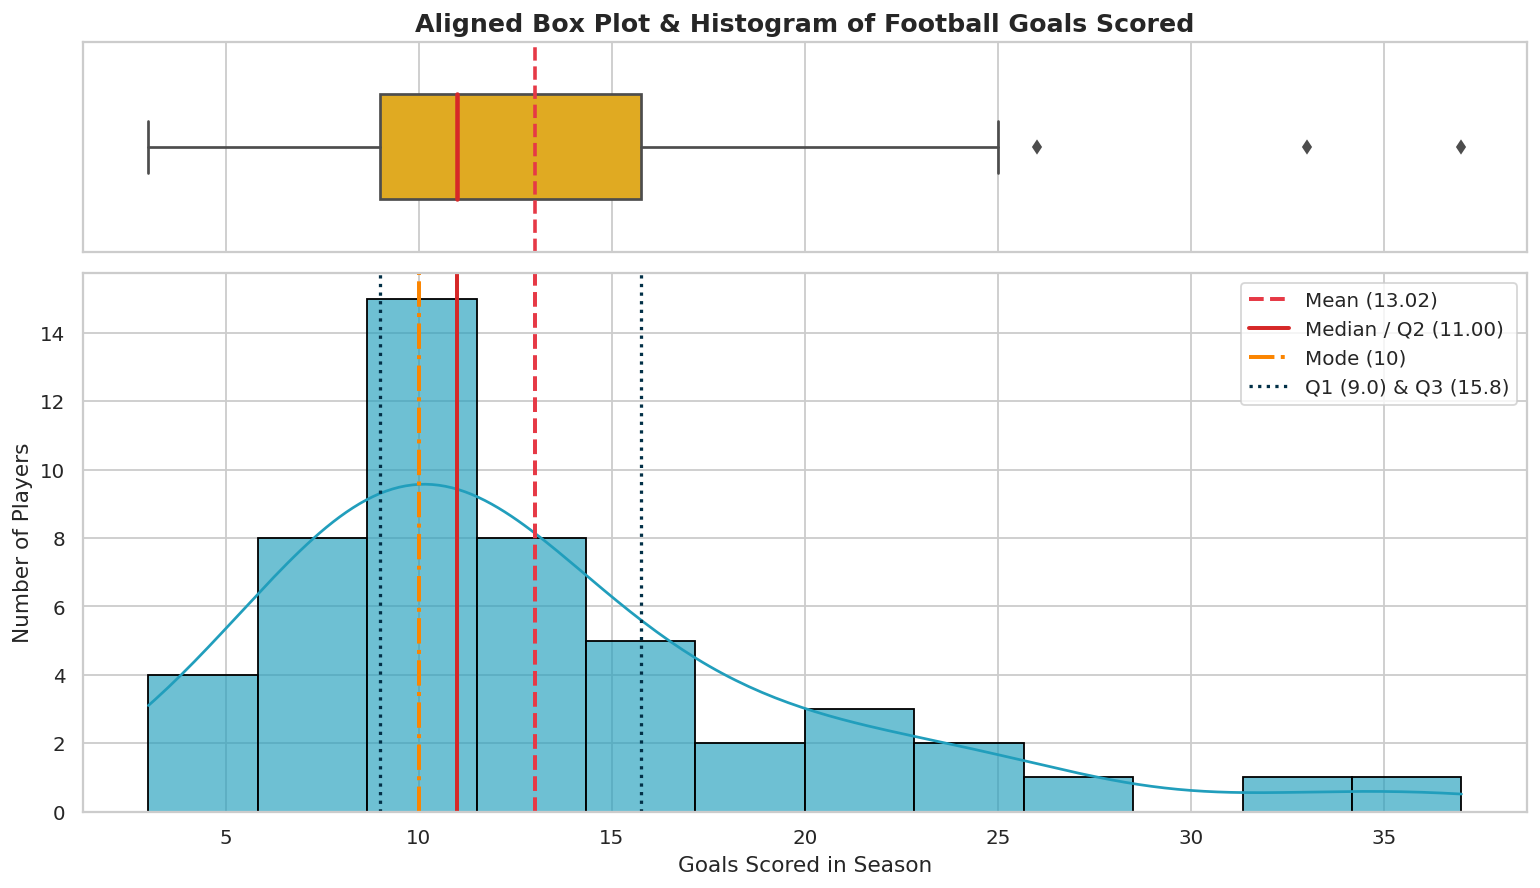

In [7]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": (0.28, 0.72)}
)

# Top subplot: Box Plot
sns.boxplot(x=df["Goals_Scored"], ax=ax_box, color="#ffb703", width=0.5,
            medianprops=dict(color="#d62828", linewidth=2.5))
ax_box.axvline(mean_goals, color="#e63946", linestyle="--", linewidth=2, label="Mean")
ax_box.set(xlabel="", title="Aligned Box Plot & Histogram of Football Goals Scored")
ax_box.title.set_size(14)
ax_box.title.set_weight("bold")

# Bottom subplot: Histogram
sns.histplot(df["Goals_Scored"], bins=12, kde=True, ax=ax_hist, color="#219ebc", edgecolor="black", alpha=0.65)
ax_hist.axvline(mean_goals, color="#e63946", linestyle="--", linewidth=2.2, label=f"Mean ({mean_goals:.2f})")
ax_hist.axvline(median_goals, color="#d62828", linestyle="-", linewidth=2.2, label=f"Median / Q2 ({median_goals:.2f})")
ax_hist.axvline(mode_goals, color="#fb8500", linestyle="-.", linewidth=2.2, label=f"Mode ({mode_goals})")
ax_hist.axvline(q1, color="#023047", linestyle=":", linewidth=1.8, label=f"Q1 ({q1:.1f}) & Q3 ({q3:.1f})")
ax_hist.axvline(q3, color="#023047", linestyle=":", linewidth=1.8)

ax_hist.set_xlabel("Goals Scored in Season", fontsize=12)
ax_hist.set_ylabel("Number of Players", fontsize=12)
ax_hist.legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

---
## 8. Bonus: Comparing Box Plots Across Player Positions

In real football analytics, we often compare distributions across groups (e.g., **Midfielders vs. Wingers vs. Forwards**). Let's plot grouped Box Plots to compare their medians and IQRs!

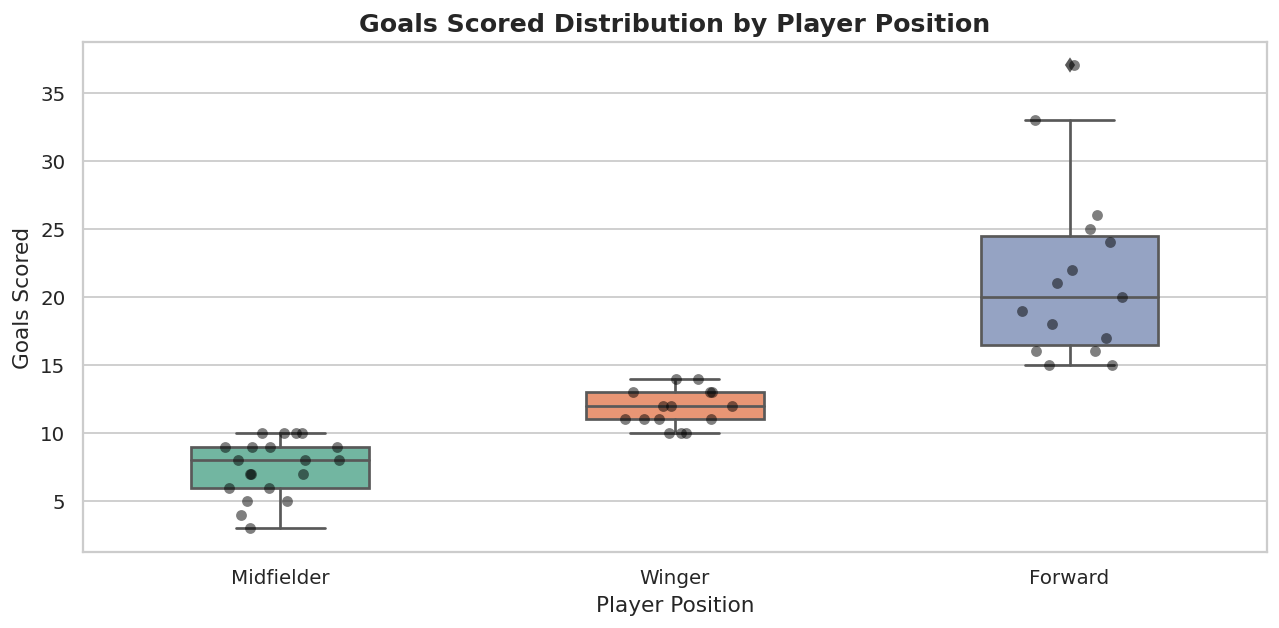

,Count,Mean,Q1,Median_Q2,Q3,IQR
Position,,,,,,
Forward,15,21.6,16.5,20.0,24.5,8.0
Midfielder,20,7.5,6.0,8.0,9.0,3.0
Winger,15,11.8,11.0,12.0,13.0,2.0


In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Position", y="Goals_Scored", palette="Set2", width=0.45)
sns.stripplot(data=df, x="Position", y="Goals_Scored", color="black", alpha=0.5, size=6, jitter=0.15)

plt.title("Goals Scored Distribution by Player Position", fontsize=14, fontweight="bold")
plt.xlabel("Player Position", fontsize=12)
plt.ylabel("Goals Scored", fontsize=12)
plt.tight_layout()
plt.show()

# Print group-wise quartiles and central tendencies
df.groupby("Position")["Goals_Scored"].agg(
    Count="count",
    Mean="mean",
    Q1=lambda x: x.quantile(0.25),
    Median_Q2="median",
    Q3=lambda x: x.quantile(0.75),
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).round(2)